In [45]:
import numpy as np
from pde_find import build_linear_system, STRidge, print_pde, TrainSTRidge

In [46]:
data_1 = np.load('../PDE_Find/dataset/1.npz')
print(data_1.files)

['u', 'x', 't']


In [47]:
u, x, t = data_1['u'], data_1['x'], data_1['t']

Text(0.5, 0.5, 't')

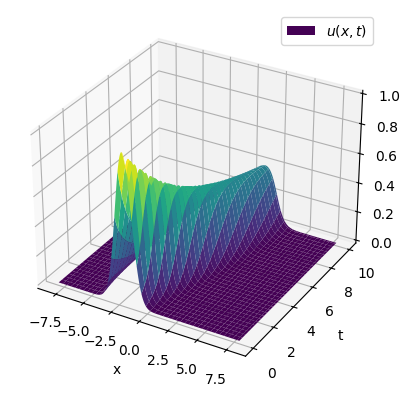

In [48]:
import matplotlib.pyplot as plt

from mpl_toolkits.mplot3d import axes3d

fig, axs = plt.subplots(1, 1, subplot_kw={'projection': '3d'})
axs.plot_surface(x, t, u, cmap='viridis')
plt.legend(['$u(x,t)$'])
plt.xlabel('x')
plt.ylabel('t')

In [49]:
# compute the spatial and temporal steps
dx = x[1,0] - x[0,0]
dt = t[0,1] - t[0,0]

In [50]:
x

array([[-8.    , -8.    , -8.    , ..., -8.    , -8.    , -8.    ],
       [-7.9375, -7.9375, -7.9375, ..., -7.9375, -7.9375, -7.9375],
       [-7.875 , -7.875 , -7.875 , ..., -7.875 , -7.875 , -7.875 ],
       ...,
       [ 7.8125,  7.8125,  7.8125, ...,  7.8125,  7.8125,  7.8125],
       [ 7.875 ,  7.875 ,  7.875 , ...,  7.875 ,  7.875 ,  7.875 ],
       [ 7.9375,  7.9375,  7.9375, ...,  7.9375,  7.9375,  7.9375]],
      dtype=float32)

In [51]:
t 

array([[ 0. ,  0.1,  0.2, ...,  9.8,  9.9, 10. ],
       [ 0. ,  0.1,  0.2, ...,  9.8,  9.9, 10. ],
       [ 0. ,  0.1,  0.2, ...,  9.8,  9.9, 10. ],
       ...,
       [ 0. ,  0.1,  0.2, ...,  9.8,  9.9, 10. ],
       [ 0. ,  0.1,  0.2, ...,  9.8,  9.9, 10. ],
       [ 0. ,  0.1,  0.2, ...,  9.8,  9.9, 10. ]], dtype=float32)

In [52]:
Ut, Theta, rhs_des = build_linear_system(u, dt, dx, D=3, P=3)
['1'] + rhs_des[1:]

['1',
 'u',
 'u^2',
 'u^3',
 'u_{x}',
 'uu_{x}',
 'u^2u_{x}',
 'u^3u_{x}',
 'u_{xx}',
 'uu_{xx}',
 'u^2u_{xx}',
 'u^3u_{xx}',
 'u_{xxx}',
 'uu_{xxx}',
 'u^2u_{xxx}',
 'u^3u_{xxx}']

In [53]:
# Solve with STRidge
w = TrainSTRidge(Theta,Ut,10**-5,1)
print("PDE derived using STRidge")
print_pde(w, rhs_des)

PDE derived using STRidge
u_t = (-1.000403 +0.000000i)uu_{x}
    + (0.100145 +0.000000i)u_{xx}
   


In [54]:
# Solve with STRidge
w = TrainSTRidge(Theta,Ut,10**-5,0.1)
print("PDE derived using STRidge")
print_pde(w, rhs_des)

PDE derived using STRidge
u_t = (-1.000403 +0.000000i)uu_{x}
    + (0.100145 +0.000000i)u_{xx}
   


In [55]:
# Solve with STRidge
w = TrainSTRidge(Theta,Ut,10**-5,1e-2)
print("PDE derived using STRidge")
print_pde(w, rhs_des)

PDE derived using STRidge
u_t = (-1.000403 +0.000000i)uu_{x}
    + (0.100145 +0.000000i)u_{xx}
   
